# Processing Culture: 10 — Resource Frames, Voice Doppelgängers, and Harm

**Companion to Lecture 06: Greed, Toxicity, and Repair**

This notebook uses small, fictional text examples to practice computational linguistics and data-science reasoning. It contrasts zero-sum and positive-sum language, then audits textual warning cues in invented voice-message transcripts. It does **not** generate or clone voices, identify a real speaker, infer intent, or establish consent.

The examples and labels are AI-generated for this teaching exercise; they are synthetic, not collected observations or independently human-annotated data. No data are downloaded, and no audio or personal information is needed.

[Lecture 06](../../lectures/lecture_06_greed_toxicity_and_repair.md) · [FTC guidance on family-emergency scams](https://consumer.ftc.gov/consumer-alerts/2023/03/scammers-use-ai-enhance-their-family-emergency-schemes) · [NIST overview of synthetic-content transparency](https://nvlpubs.nist.gov/nistpubs/ai/NIST.AI.100-4.pdf)

## Questions and limits

1. Which words and phrases frame a resource as a fixed contest, and which frame cooperation as able to create shared gains?
2. What can simple lexical cues flag in a high-stakes message, and what can they not tell us?
3. How do sample construction, annotation, and power affect the conclusions we draw?

A zero-sum or positive-sum label here describes the **sentence's framing**, not the world itself. A larger total surplus does not guarantee fair distribution, and a phrase-based warning score is not an authenticity detector.

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(2026)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 110)
print('Environment ready: local, fictional examples only.')

Environment ready: local, fictional examples only.


## 1. A tiny synthetic corpus of resource frames

The examples below are invented to make the labels inspectable. `zero_sum` means the sentence presents one party's gain as another's loss or treats the available resource as fixed. `positive_sum` means it emphasizes cooperation or expanding shared benefit. These are analytical labels for the wording—not a judgment that a real policy or resource is actually zero-sum.

In [2]:
frame_records = [
    ('z01', 'zero_sum', 'If they get more seats, our community loses influence.'),
    ('z02', 'zero_sum', 'Every raise for workers means less profit for owners.'),
    ('z03', 'zero_sum', 'There is only one home available; if I get it, someone else cannot.'),
    ('z04', 'zero_sum', 'Their gain is our loss.'),
    ('z05', 'zero_sum', 'We have to protect our share before someone takes it.'),
    ('z06', 'zero_sum', 'A limited grant has one winner, so applicants compete.'),
    ('z07', 'zero_sum', 'More funding for them means less for us.'),
    ('z08', 'zero_sum', 'A fixed number of seats must be divided among candidates.'),
    ('p01', 'positive_sum', 'We can build more homes and share the benefits.'),
    ('p02', 'positive_sum', 'A public library gives everyone more ways to learn.'),
    ('p03', 'positive_sum', 'Cooperative childcare frees time for families and creates paid work.'),
    ('p04', 'positive_sum', 'Cleaner transit can reduce costs and improve access.'),
    ('p05', 'positive_sum', 'We can expand the grant pool and fund more projects.'),
    ('p06', 'positive_sum', 'Better tools can raise output while we share gains.'),
    ('p07', 'positive_sum', 'A joint project lets both teams contribute and benefit.'),
    ('p08', 'positive_sum', 'Preventing illness helps workers, families, and employers.'),
]

frames = pd.DataFrame(frame_records, columns=['id', 'frame', 'text'])
assert frames['id'].is_unique
assert set(frames['frame']) == {'zero_sum', 'positive_sum'}
display(frames)

,id,frame,text
0,z01,zero_sum,"If they get more seats, our community loses influence."
1,z02,zero_sum,Every raise for workers means less profit for owners.
2,z03,zero_sum,"There is only one home available; if I get it, someone else cannot."
3,z04,zero_sum,Their gain is our loss.
4,z05,zero_sum,We have to protect our share before someone takes it.
5,z06,zero_sum,"A limited grant has one winner, so applicants compete."
6,z07,zero_sum,More funding for them means less for us.
7,z08,zero_sum,A fixed number of seats must be divided among candidates.
8,p01,positive_sum,We can build more homes and share the benefits.
9,p02,positive_sum,A public library gives everyone more ways to learn.


## 2. Token frequencies and lexical contrasts

We lowercase and tokenize words while retaining apostrophes and hyphens. We deliberately do **not** remove negation such as `not`, `no`, or `never`: dropping it can reverse a statement's meaning. Frequency differences can suggest what to inspect, but with sixteen crafted sentences they are demonstrations, not estimates of public opinion or policy effects.

,frame,token,count,per_100_tokens
2,positive_sum,and,6,8.45
8,positive_sum,can,4,5.63
33,positive_sum,more,3,4.23
51,positive_sum,we,3,4.23
0,positive_sum,a,2,2.82
18,positive_sum,families,2,2.82
43,positive_sum,share,2,2.82
45,positive_sum,the,2,2.82
69,zero_sum,for,4,5.48
93,zero_sum,our,3,4.11


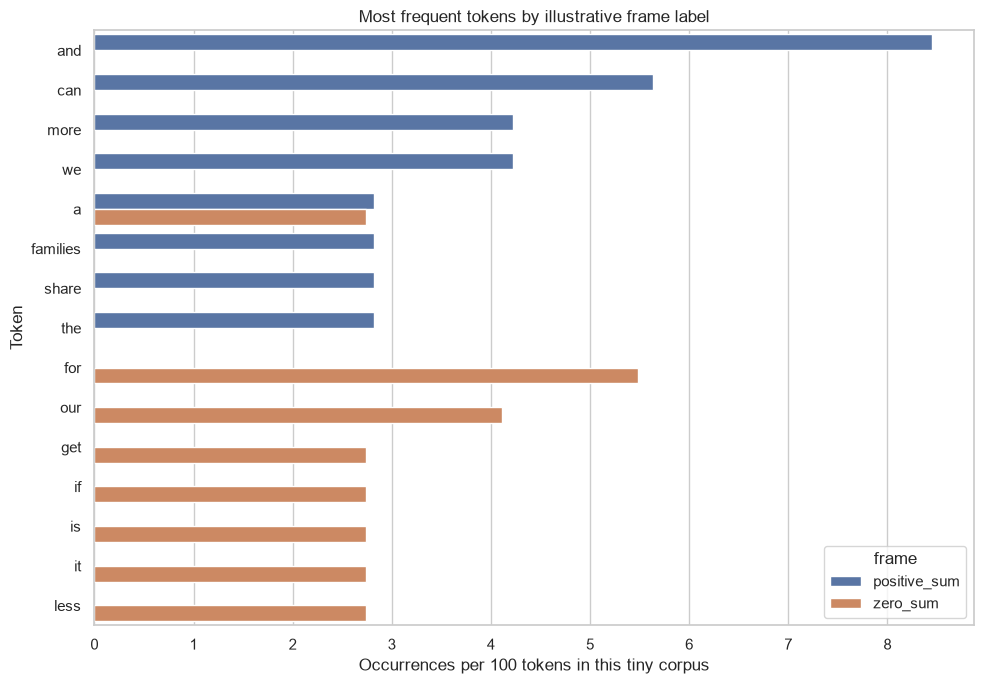

In [3]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:['-][a-z0-9]+)*")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

frames['tokens'] = frames['text'].map(tokenize)
token_rows = [
    {'id': row.id, 'frame': row.frame, 'token': token}
    for row in frames.itertuples()
    for token in row.tokens
]
token_table = pd.DataFrame(token_rows)
token_counts = token_table.groupby(['frame', 'token']).size().rename('count').reset_index()
token_counts['total_tokens'] = token_counts['frame'].map(token_table.groupby('frame').size())
token_counts['per_100_tokens'] = 100 * token_counts['count'] / token_counts['total_tokens']

top_terms = (
    token_counts.sort_values(['frame', 'per_100_tokens'], ascending=[True, False])
    .groupby('frame', as_index=False, group_keys=False)
    .head(8)
)
display(top_terms[['frame', 'token', 'count', 'per_100_tokens']].round(2))

plt.figure(figsize=(10, 7))
sns.barplot(data=top_terms, x='per_100_tokens', y='token', hue='frame')
plt.xlabel('Occurrences per 100 tokens in this tiny corpus')
plt.ylabel('Token')
plt.title('Most frequent tokens by illustrative frame label')
plt.tight_layout()
plt.show()

## 3. TF–IDF and sentence similarity

The next cell computes term frequency–inverse document frequency directly, then cosine similarity between sentences. Similarity is lexical overlap, not agreement, truth, shared intent, or common authorship. Near-duplicate wording can arise from templates; different wording can express the same idea. These measures are useful for exploration, never voice or identity verification.

,more_positive_sum,more_zero_sum
and,0.163,0.000
can,0.124,0.000
families,0.083,0.000
the,0.072,0.000
we,0.062,0.000
employers,0.056,0.000
our,0.000,-0.126
for,0.000,-0.114
is,0.000,-0.095
less,0.000,-0.081


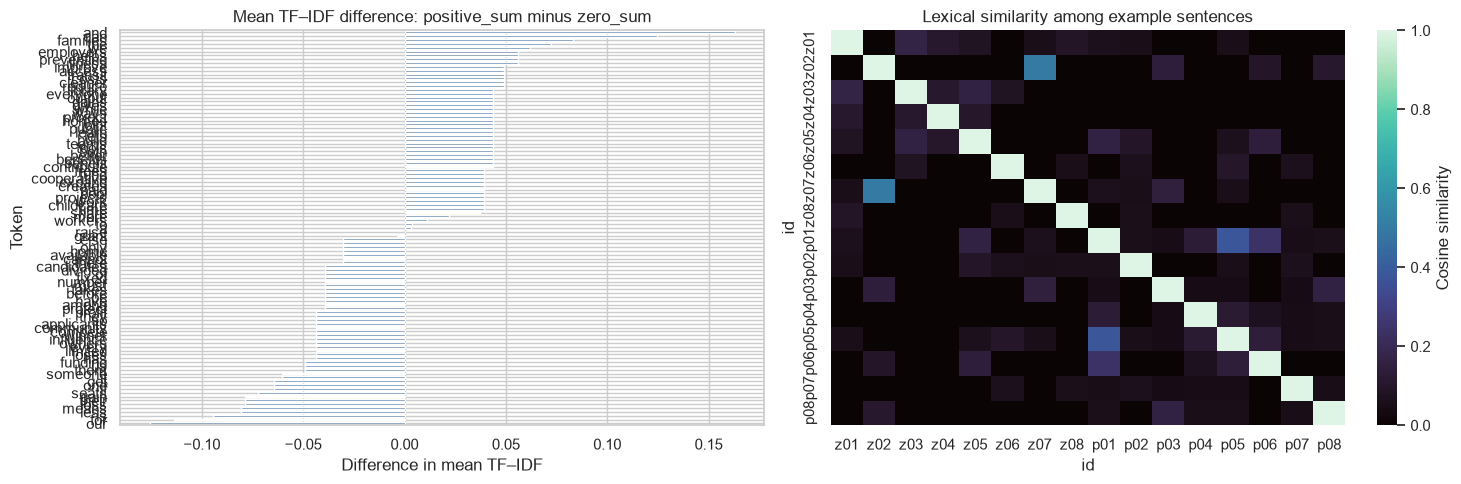

In [4]:
vocabulary = sorted({token for tokens in frames['tokens'] for token in tokens})
count_matrix = pd.DataFrame(
    [{term: Counter(tokens).get(term, 0) for term in vocabulary} for tokens in frames['tokens']],
    index=frames['id'],
)
term_frequency = count_matrix.div(count_matrix.sum(axis=1), axis=0)
document_frequency = (count_matrix > 0).sum(axis=0)
inverse_document_frequency = np.log((1 + len(frames)) / (1 + document_frequency)) + 1
tfidf = term_frequency.mul(inverse_document_frequency, axis=1)

labels = frames.set_index('id')['frame']
mean_tfidf = tfidf.assign(frame=labels).groupby('frame').mean().T
contrast = mean_tfidf['positive_sum'] - mean_tfidf['zero_sum']
contrast_view = pd.concat([
    contrast.nlargest(6).rename('more_positive_sum'),
    contrast.nsmallest(6).rename('more_zero_sum'),
], axis=1).fillna(0)
display(contrast_view.round(3))

norms = np.linalg.norm(tfidf.to_numpy(), axis=1, keepdims=True)
normalized = np.divide(tfidf.to_numpy(), norms, out=np.zeros_like(tfidf.to_numpy()), where=norms != 0)
cosine = normalized @ normalized.T
similarity = pd.DataFrame(cosine, index=frames['id'], columns=frames['id'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
contrast.sort_values().plot.barh(ax=axes[0], color='#5078A0')
axes[0].set_title('Mean TF–IDF difference: positive_sum minus zero_sum')
axes[0].set_xlabel('Difference in mean TF–IDF')
axes[0].set_ylabel('Token')
sns.heatmap(similarity, cmap='mako', vmin=0, vmax=1, ax=axes[1], cbar_kws={'label': 'Cosine similarity'})
axes[1].set_title('Lexical similarity among example sentences')
plt.tight_layout()
plt.show()

## 4. A phrase-cue audit for invented voice-message transcripts

These examples are text-only and fictional. The labels mark whether a human reviewer would choose to **verify through another channel before acting**. A suspicious label is not a finding of fraud; an ordinary label is not proof of safety. We intentionally include an urgent but harmless message (a likely false positive) and a vague high-stakes request with none of the listed phrases (a likely false negative).

In [5]:
message_records = [
    ('m01', 'Mom, I lost my phone. I am at the station. Send $400 right now and do not call.', 'verify'),
    ('m02', 'This is your manager. I need your one-time code to unlock payroll. Keep this between us.', 'verify'),
    ('m03', 'Hi, it is Alex. I was in an accident. Buy gift cards and text me the numbers.', 'verify'),
    ('m04', 'I need you to wire money before the bank closes. Do not tell anyone.', 'verify'),
    ('m05', 'It is me. Can you make a payment to the new account? I will explain when I see you.', 'verify'),
    ('m06', 'Urgent: our meeting moved to 3 PM. Can you confirm the calendar invite?', 'ordinary'),
    ('m07', 'Here is my voice note about the weekend. Call me when you have time.', 'ordinary'),
    ('m08', 'Reminder: please send the invoice tomorrow. No rush.', 'ordinary'),
]

messages = pd.DataFrame(message_records, columns=['message_id', 'transcript', 'review_label'])
display(messages)

,message_id,transcript,review_label
0,m01,"Mom, I lost my phone. I am at the station. Send $400 right now and do not call.",verify
1,m02,This is your manager. I need your one-time code to unlock payroll. Keep this between us.,verify
2,m03,"Hi, it is Alex. I was in an accident. Buy gift cards and text me the numbers.",verify
3,m04,I need you to wire money before the bank closes. Do not tell anyone.,verify
4,m05,It is me. Can you make a payment to the new account? I will explain when I see you.,verify
5,m06,Urgent: our meeting moved to 3 PM. Can you confirm the calendar invite?,ordinary
6,m07,Here is my voice note about the weekend. Call me when you have time.,ordinary
7,m08,Reminder: please send the invoice tomorrow. No rush.,ordinary


The transparent baseline below flags exact phrases associated with urgency, secrecy, money, or security codes. It is intentionally crude: it does not learn from a large representative dataset, and it does not listen to audio. Cue counts support a human review decision; they cannot authenticate a voice or prove a speaker's identity, intent, or consent.

In [6]:
RISK_CUES = [
    'send money', 'send $', 'wire money', 'gift cards', 'one-time code',
    'verification code', 'do not call', 'do not tell',
    'keep this between us', 'right now', 'urgent',
]

def find_risk_cues(text):
    normalized_text = text.lower()
    return [cue for cue in RISK_CUES if cue in normalized_text]

messages['matched_cues'] = messages['transcript'].map(find_risk_cues)
messages['cue_count'] = messages['matched_cues'].map(len)
messages['baseline_flag'] = np.where(messages['cue_count'] > 0, 'verify', 'ordinary')
display(messages[['message_id', 'review_label', 'baseline_flag', 'matched_cues']])

,message_id,review_label,baseline_flag,matched_cues
0,m01,verify,verify,"[send $, do not call, right now]"
1,m02,verify,verify,"[one-time code, keep this between us]"
2,m03,verify,verify,[gift cards]
3,m04,verify,verify,"[wire money, do not tell]"
4,m05,verify,ordinary,[]
5,m06,ordinary,verify,[urgent]
6,m07,ordinary,ordinary,[]
7,m08,ordinary,ordinary,[]


phrase baseline,ordinary,verify
review label,,
ordinary,2,1
verify,1,4


Toy-corpus counts — true negatives: 2, false positives: 1, false negatives: 1, true positives: 4


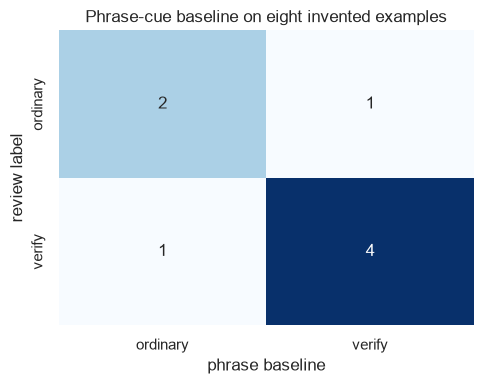

In [7]:
class_order = ['ordinary', 'verify']
confusion = pd.DataFrame(
    [[
        int(((messages['review_label'] == actual) & (messages['baseline_flag'] == predicted)).sum())
        for predicted in class_order
    ] for actual in class_order],
    index=pd.Index(class_order, name='review label'),
    columns=pd.Index(class_order, name='phrase baseline'),
)
display(confusion)

tn = confusion.loc['ordinary', 'ordinary']
fp = confusion.loc['ordinary', 'verify']
fn = confusion.loc['verify', 'ordinary']
tp = confusion.loc['verify', 'verify']
print(f'Toy-corpus counts — true negatives: {tn}, false positives: {fp}, false negatives: {fn}, true positives: {tp}')
assert (tn, fp, fn, tp) == (2, 1, 1, 4)

plt.figure(figsize=(5, 4))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Phrase-cue baseline on eight invented examples')
plt.tight_layout()
plt.show()

### Interpret the misses, not just the score

- `m06` is a false positive because the word *urgent* appears in a routine scheduling message.
- `m05` is a false negative because the risky payment request uses wording absent from the cue list.
- The denominator is eight invented examples. Precision, recall, and accuracy computed here would say almost nothing about real-world performance.
- Even a perfect text classifier would classify only the transcript under its annotation scheme. It would not establish who spoke, whether the audio was edited, whether the person consented, or what they intended.

For an actual urgent request: pause; verify on a separately obtained, trusted channel; do not send money or share passwords or one-time codes based on voice alone; preserve the original message and context; and report suspected impersonation through the relevant service. Do not forward the clip as authentic. No listening test or detector can guarantee that a voice is genuine.

## 5. Consent and data ethics

Voice synthesis can support augmentative communication, a person's chosen voice when speech changes, translation, and creative work. Ethical use needs more than access to a sample: consent should specify purpose, audience, duration, review rights, disclosure, compensation where appropriate, and how use can be limited or revoked. Permission to record or model a voice is not blanket permission to generate arbitrary statements in that voice. Avoid uploading private recordings to untrusted services, and do not use a loved one's voice or transcript as a classroom dataset without their explicit, informed permission.

Synthetic-content provenance tools may provide useful context when present, but a label does not prove that a statement is true, and no label does not prove that a recording is authentic. The safest workflow is provenance plus independent verification, consent, and clear accountability.

## 6. Exercises: move from toy data to responsible research

1. **Annotation design:** Write a short codebook defining zero-sum framing, positive-sum framing, mixed framing, and uncertainty. Have at least two annotators independently label a properly licensed, non-sensitive text sample; report disagreements rather than hiding them.
2. **Negation and context:** Add examples such as *not a zero-sum game*, quotations, sarcasm, and conditional statements. Compare results with negation preserved versus removed. Explain why either approach can fail.
3. **Dataset shift:** Test the same codebook on another domain or time period. Inspect which categories or voices are underrepresented. Do not interpret lexical differences as differences in people's motives.
4. **Evaluation:** Build a held-out test set only after defining the task and annotation process. Report class balance, confusion counts, and uncertainty; compare a keyword baseline with a model only if the dataset is large and representative enough.
5. **Voice-message safeguards:** Keep the examples text-only. Design a verification protocol that does not depend on voice similarity, public personal facts, or a code phrase as the sole proof. Consider who may be harmed by false alarms as well as missed scams.
6. **Pie and distribution:** Add human-coded examples that distinguish expanding shared benefits from redistributing fixed resources. Ask who owns the gains and who bears externalized costs in each case.

### Takeaway

Computational linguistics can make patterns in wording visible. It cannot turn wording into transparent access to a person's interior life. A voice that sounds familiar is still a claim requiring provenance and context; a growing surplus is still a distributional question.